# Sort it once, and sort it stably

Sorting is the operation you will run most often without noticing, inside every
`groupby`, every ranking, every median. This notebook shows why the algorithm
matters even though the result is the same: how fast the lecture's algorithms
are on growing data, what stability means for a ranking with ties, and what
you gain once a list is sorted.

## 1. Three algorithms, one list

Selection sort and mergesort are written below as in the lecture, with arrays
indexed from 0 as Python wants. Python's built-in `sorted` is Timsort, a
mergesort variant written in C. We time all three on random lists of growing
size.

In [1]:
import random, time

def selection_sort(A):
    n = len(A)
    for i in range(n - 1):
        smallest = i
        for j in range(i + 1, n):
            if A[j] < A[smallest]:
                smallest = j
        A[i], A[smallest] = A[smallest], A[i]
    return A

def merge_sort(A):
    if len(A) <= 1:
        return A
    mid = len(A) // 2
    L, R = merge_sort(A[:mid]), merge_sort(A[mid:])
    out, i, j = [], 0, 0
    while i < len(L) and j < len(R):          # merge: take the smaller head
        if L[i] <= R[j]: out.append(L[i]); i += 1
        else:            out.append(R[j]); j += 1
    return out + L[i:] + R[j:]

def timed(f, A):
    t0 = time.perf_counter(); f(list(A)); return time.perf_counter() - t0

rnd = random.Random(7)
ns = [500, 1000, 2000, 4000]
times = {"selection sort": [], "mergesort": [], "sorted (built-in)": []}
for n in ns:
    A = [rnd.random() for _ in range(n)]
    times["selection sort"].append(timed(selection_sort, A))
    times["mergesort"].append(timed(merge_sort, A))
    times["sorted (built-in)"].append(timed(sorted, A))
    print(f"n = {n:5}   " + "   ".join(f"{k}: {v[-1]:8.4f} s" for k, v in times.items()))

n =   500   selection sort:   0.0028 s   mergesort:   0.0005 s   sorted (built-in):   0.0000 s
n =  1000   selection sort:   0.0109 s   mergesort:   0.0007 s   sorted (built-in):   0.0001 s
n =  2000   selection sort:   0.0408 s   mergesort:   0.0017 s   sorted (built-in):   0.0002 s


n =  4000   selection sort:   0.1684 s   mergesort:   0.0038 s   sorted (built-in):   0.0004 s


Each doubling of $n$ multiplies the selection sort time by about four, the
mergesort time by a little more than two. That is $n^2$ against $n \log n$, and
on a log-log plot the two are lines of different slope. The built-in sort has the
same slope as mergesort and a much smaller constant, because it runs in C rather
than in interpreted Python: the algorithm decides the slope, the implementation
decides the offset.

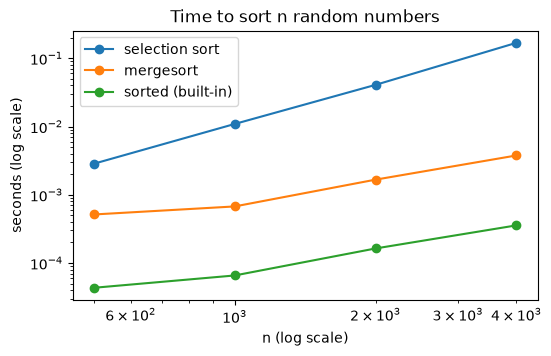

predicted for n = 1,000,000: selection sort 3 hours, mergesort 2 s


In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
for k, v in times.items():
    ax.plot(ns, v, "o-", label=k)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n (log scale)"); ax.set_ylabel("seconds (log scale)")
ax.legend(); ax.set_title("Time to sort n random numbers")
plt.show()

n = 1_000_000
print(f"predicted for n = {n:,}: selection sort {times['selection sort'][-1] * (n / ns[-1]) ** 2 / 3600:.0f} hours,"
      f" mergesort {times['mergesort'][-1] * (n / ns[-1]) * 1.8:.0f} s")

## 2. Stability: what happens to ties

Suppose respondents answered a survey in a known order and we rank them by age.
Several have the same age. A stable sort keeps equal elements in their original
order; an unstable one is free to reorder them. Selection sort is unstable, the
built-in sort is stable. Watch what happens to the three 34-year-olds.

In [3]:
respondents = [("Anna", 34), ("Ben", 29), ("Carla", 34), ("Dmitri", 41),
               ("Elif", 34), ("Farid", 29), ("Gao", 25)]          # in the order they answered

def selection_sort_by(A, key):
    n = len(A)
    for i in range(n - 1):
        smallest = i
        for j in range(i + 1, n):
            if key(A[j]) < key(A[smallest]):
                smallest = j
        A[i], A[smallest] = A[smallest], A[i]
    return A

age = lambda r: r[1]
print("original order: ", [name for name, _ in respondents])
print("built-in sort:  ", [name for name, _ in sorted(respondents, key=age)])
print("selection sort: ", [name for name, _ in selection_sort_by(list(respondents), key=age)])

original order:  ['Anna', 'Ben', 'Carla', 'Dmitri', 'Elif', 'Farid', 'Gao']
built-in sort:   ['Gao', 'Ben', 'Farid', 'Anna', 'Carla', 'Elif', 'Dmitri']
selection sort:  ['Gao', 'Ben', 'Farid', 'Elif', 'Carla', 'Anna', 'Dmitri']


The built-in sort lists the 34-year-olds as Anna, Carla, Elif, the order they
answered in. Selection sort lists them as Elif, Carla, Anna, the reverse: its
first swap sent Anna to the end of the array to make room for Gao, and the later
swaps never restored her. The order of equal elements is an accident of the
swaps, and with a different input order it would be a different accident.

This matters whenever you sort in stages. To order respondents by region and,
within each region, by age, the standard method is to sort by age first and then
by region with a stable sort, which keeps the age order inside each region. With
an unstable sort, the second sort destroys the first. Pandas's `sort_values`
defaults to an unstable quicksort; pass `kind="stable"` when the order of ties
matters, and know that the same applies to `numpy.argsort`.

## 3. What a sorted list buys you

Sorting costs $n \log n$ once. After that, every lookup by binary search costs
$\log_2 n$ comparisons instead of up to $n$. With a hundred thousand ids and ten
thousand lookups, the sort pays for itself many times over.

In [4]:
from bisect import bisect_left

ids = [rnd.randrange(10**9) for _ in range(100_000)]
queries = [rnd.choice(ids) for _ in range(5_000)] + [rnd.randrange(10**9) for _ in range(5_000)]

t0 = time.perf_counter()
found_scan = sum(q in ids for q in queries)                       # linear scan, unsorted
t_scan = time.perf_counter() - t0

t0 = time.perf_counter()
sorted_ids = sorted(ids)
t_sort = time.perf_counter() - t0
t0 = time.perf_counter()
found_bisect = sum(sorted_ids[bisect_left(sorted_ids, q):bisect_left(sorted_ids, q) + 1] == [q] for q in queries)
t_bisect = time.perf_counter() - t0

print(f"scan the unsorted list:   {t_scan:6.2f} s   ({found_scan} found)")
print(f"sort once:                {t_sort:6.3f} s")
print(f"then binary search:       {t_bisect:6.3f} s   ({found_bisect} found)")

scan the unsorted list:     3.99 s   (5000 found)
sort once:                 0.027 s
then binary search:        0.011 s   (5000 found)


The scan takes seconds, the sort plus ten thousand binary searches a fraction
of one. Every index in a database, every `merge` in pandas, every median and
percentile starts by sorting for exactly this reason: sorted data can be
searched, merged and summarized in logarithmic or linear time, unsorted data
cannot.

**What we used:** the formal sorting problem and stability
([session 7, sections 2 and 3](../Transcripts/07-SortingAlgorithms.md#3-stable-and-unstable-sorting)),
selection sort ([section 4](../Transcripts/07-SortingAlgorithms.md#4-iterative-sorting)),
mergesort ([section 6](../Transcripts/07-SortingAlgorithms.md#6-mergesort)),
why sorting matters for us ([section 9](../Transcripts/07-SortingAlgorithms.md#9-why-sorting-matters-for-us))
and binary search from [session 3, section 5](../Transcripts/03-DataStructures.md#5-binary-search).